In [2]:
from pathlib import Path
from pydotthz import DotthzFile
from scipy.ndimage import gaussian_filter1d
import pyvista as pv
import os
import scipy.constants
import matplotlib.pyplot as plt
from scipy.ndimage import label, binary_opening, generate_binary_structure
import numpy as np
from thz_deconvolution import Deconvolution
from surface_extraction import get_thz_file_from_path
from cmcrameri import cm


def percentile_scale(cube, percentile=97.0):
    """
    cube: 3D ndarray (nx, ny, nt) with bipolar time-domain signals.
    Returns:
      scaled_float: same shape, clipped symmetrically to ±p97 and scaled to [-1, 1]
      scaled_u8: same shape, mapped to 8-bit grayscale [0, 255] (white=positive, black=negative)
      p97: the symmetric clip value used
    """
    if not isinstance(cube, np.ndarray) or cube.ndim != 3:
        raise ValueError("cube must be a 3D numpy array (nx, ny, nt)")

    # robust symmetric limit from absolute amplitudes
    p = np.percentile(np.abs(cube), percentile)

    # avoid divide-by-zero if the cube is all zeros
    if p == 0:
        scaled_float = np.zeros_like(cube, dtype=np.float32)
        scaled_u8 = np.full_like(cube, 128, dtype=np.uint8)  # mid-gray
        return scaled_float, scaled_u8, p

    # clip symmetrically and scale to [-1, 1]
    clipped = np.clip(cube, -p, p)
    scaled_float = (clipped / p).astype(np.float32)

    # map [-1, 1] -> [0, 255] (0=black negative, 128=mid-gray zero, 255=white positive)
    scaled_u8 = np.round((scaled_float + 1.0) * 0.5 * 255.0).astype(np.uint8)

    return scaled_float, scaled_u8, p

In [111]:

path = Path("/Users/linus/Documents/COC_PEBBLE_CoDA_T3_dust_low_res_vac_4/data_image_rfl")

path = Path("/Users/linus/Documents/ICE_PEBBLE_CoDA_T3_dust_low_res_vac_6_small_fov_slow/data_image_rfl")

path = Path(
    "/Users/linus/Documents/ICE_PEBBLE_SPHERE_CoDA_T3_dust_low_res_vac_7_fast_focus_on_sohere_top/data_image_rfl")

path = Path(
    "/Users/linus/Documents/ICE_PEBBLE_SPHERE_CoDA_T3_dust_low_res_vac_9_fast_focus_on_sohere_top/data_image_rfl")

path = Path(
    "/Users/linus/Documents/ICE_PEBBLE_SPHERE_CoDA_T3_dust_high_res_vac_9_fast_focus_on_sohere_top/data_image_rfl")

# path = Path(
#     "/Users/linus/Documents/ICE_PEBBLE_SPHERE_CoDA_T3_dust_low_res_vac_10_fast_focus_on_sphere_top/data_image_rfl")

path = get_thz_file_from_path(path)

with DotthzFile(path) as psf_data:
    key = list(psf_data.keys())[0]
    dx = float(psf_data[key].metadata['dx [mm]'])
    dy = float(psf_data[key].metadata['dy [mm]'])
    x_min = float(psf_data[key].metadata['x_min [mm]'])
    x_max = float(psf_data[key].metadata['x_max [mm]'])
    y_min = float(psf_data[key].metadata['y_min [mm]'])
    y_max = float(psf_data[key].metadata['y_max [mm]'])
    width = int(float(psf_data[key].metadata['width']))
    height = int(float(psf_data[key].metadata['height']))
    datasets = psf_data[key].datasets

    # from the first dataset, extract the image:
    times = np.array(datasets["time"])
    traces = np.array(datasets["dataset"])

traces = traces[::, ::, :]

# Decon = Deconvolution(psf_path=Path("psf_data/psf.npz"), low_cut=0.1, high_cut=5.0)

low_cut = 0.2
high_cut = 0.5

Decon = Deconvolution(
    knife_edge_x_path=Path("psf_data/example_beam_width/measurement_x/data/1750085285.8557956_data.thz"),
    knife_edge_y_path=Path("psf_data/example_beam_width/measurement_y/data/1750163177.929295_data.thz"),
    low_cut=low_cut, high_cut=high_cut, start_freq=low_cut, end_freq=high_cut)

traces_old = traces
deconvolved_traces = Decon.apply_deconvolution(traces, x_min, x_max, width, y_min, y_max, height, max_iter=100)
traces = deconvolved_traces

# p = traces[::, ::, times < 1912]
# t = times[times < 1912]

traces = traces[::, ::, :]
times = times[:]

Loading x raw measurements...
Loading y raw measurements...
Extracting the center of the PSF...
Center of the PSF: (-0.05000000000000071, -0.8499999999999996)
Creating 20 log-spaced filters...
Fitting beam widths...


100%|██████████| 20/20 [00:00<00:00, 72.61it/s]


Extracting the center of the PSF...
Center of the PSF: (-1.5500000000000003, -0.6500000000000004)
Creating 20 log-spaced filters...
Fitting beam widths...


100%|██████████| 20/20 [00:00<00:00, 76.24it/s]


Loading cached deconvolution result (hash: eea97efc...)


100%|██████████| 240/240 [00:00<00:00, 15142.12it/s]


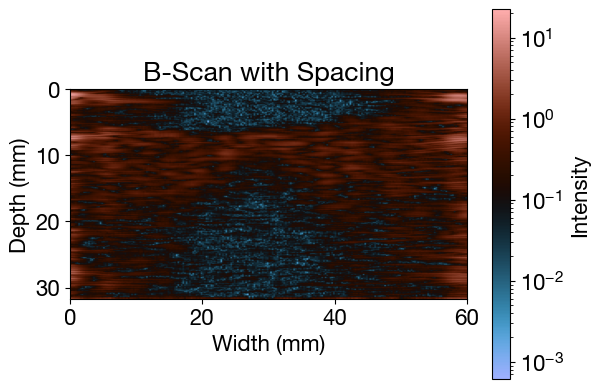

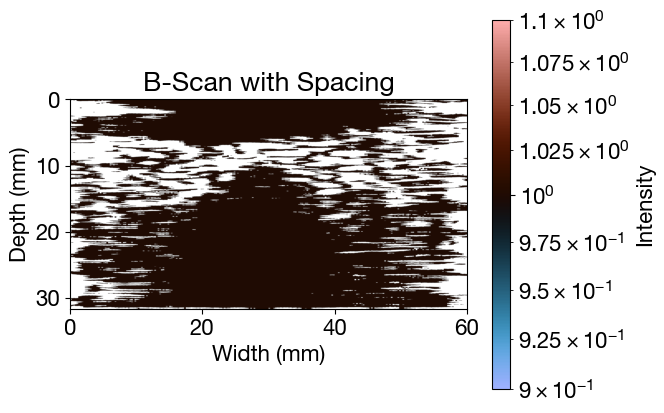

In [112]:
from surface_extraction import get_thickness
from tqdm import tqdm
from envelope import gaussian_kernel1d, convolve1d

w, h, d = traces.shape
b_scan = traces[:, w//2 - 10, :]
# b_scan = traces[h//2, :, :]

b_scan_convolved = np.zeros_like(b_scan)

sigma = 6
kernel = gaussian_kernel1d(sigma=sigma, radius=sigma * 3)

for x in tqdm(range(traces.shape[0])):
    convolved_data = convolve1d(np.abs(b_scan[x, :]), kernel)
    b_scan_convolved[x] = convolved_data
   #  b_scan_convolved[x] = scipy.signal.hilbert(np.abs(b_scan[x])**0.5).imag

spacing_x = dx
spacing_y = dy

n_COC = 1.0

spacing_z = (get_thickness(times[0], times[1]) * 1000) / n_COC

extent = [0, b_scan.shape[1] * spacing_z, 0, b_scan.shape[0] * spacing_x]

# Plot using imshow with the calculated extent
iamge = b_scan_convolved
image = iamge.T ** 1

extent = [0, b_scan.shape[0] * spacing_x, b_scan.shape[1] * spacing_z,0]
plt.ylabel("Depth (mm)")
plt.imshow(image, extent=extent, aspect='1',norm="log", cmap=cm.berlin)
plt.xlabel("Width (mm)")
plt.title("B-Scan with Spacing")
plt.colorbar(label="Intensity")
plt.savefig(f"b_scan_convolved_{path.name}.png", dpi=300)
plt.show()

# Apply thresholding to highlight voids
image_mask = image.copy()
threshold = 0.3
image_mask[image_mask > threshold] = 0
image_mask[(image_mask < threshold) & (image_mask != 0)] = 1

extent = [0, b_scan.shape[0] * spacing_x, b_scan.shape[1] * spacing_z,0]
plt.ylabel("Depth (mm)")
plt.imshow(image_mask, extent=extent, aspect='1',norm="log", cmap=cm.berlin)
plt.xlabel("Width (mm)")
plt.title("B-Scan with Spacing")
plt.colorbar(label="Intensity")
plt.show()

# from scipy.ndimage import convolve
#
#
# # Threshold the image to create a binary mask
# threshold = 0.3
# binary_mask = (image < threshold).astype(int)
#
# # Define a kernel for local density calculation
# kernel_size = 5  # Adjust the size based on the scale of voids
# kernel = np.ones((kernel_size, kernel_size))
#
# # Calculate local density
# local_density = convolve(binary_mask, kernel, mode='constant')
#
# # Threshold the local density to isolate large voids
# density_threshold = 20  # Adjust this value to control the void size
# large_voids_mask = (local_density > density_threshold).astype(int)
#
# # Plot the large voids
# plt.ylabel("Depth (mm)")
# plt.imshow(large_voids_mask, extent=extent, aspect='1', cmap=cm.berlin)
# plt.xlabel("Width (mm)")
# plt.title("Large Voids Based on Local Density")
# plt.colorbar(label="Intensity")
# plt.savefig("large_voids_local_density.png", dpi=300)
# plt.show()


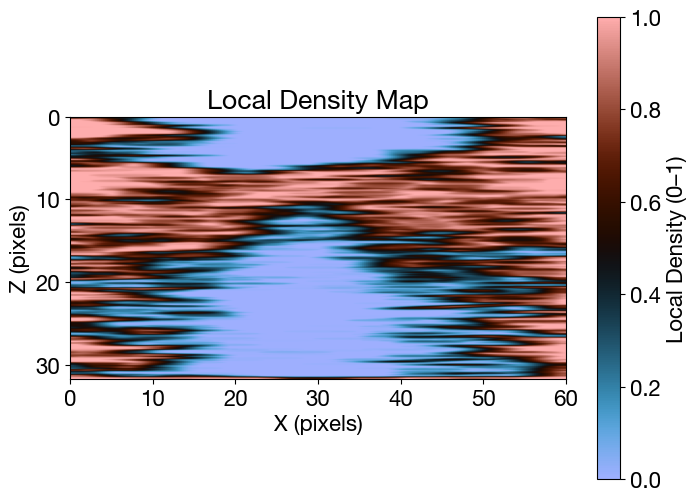

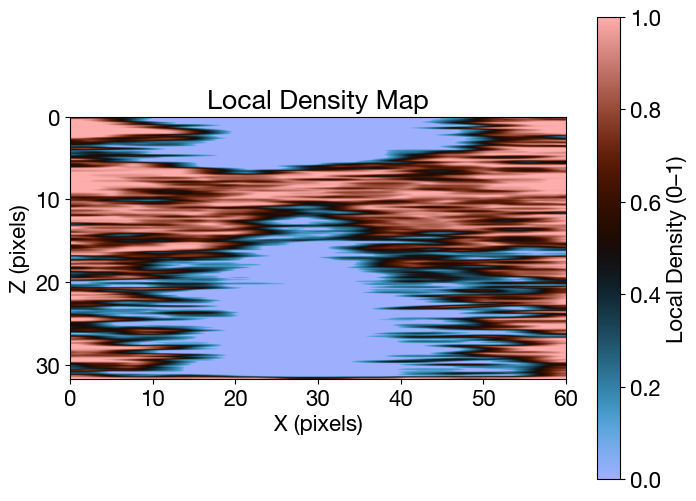

In [113]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage.morphology import disk

# Example: threshold to classify solid (1) vs void (0)
threshold = 0.2 ** 1
solid_mask = (image >= threshold).astype(np.uint8)

# Choose neighborhood radius (in pixels)
R = 18  # adjust based on resolution

kernel = disk(R).astype(float)  # circular window
kernel_size = kernel.sum()

local_density = ndi.convolve(solid_mask.astype(float), kernel) / kernel_size

plt.figure(figsize=(8,6))
plt.imshow(local_density, extent=extent, aspect='1', cmap=cm.berlin)
plt.colorbar(label="Local Density (0–1)")
plt.title("Local Density Map")
plt.xlabel("X (pixels)")
plt.ylabel("Z (pixels)")
plt.show()

mask = local_density.copy()

mask[mask < 0.1] = 0.0

plt.figure(figsize=(8,6))
plt.imshow(mask, extent=extent, aspect='1', cmap=cm.berlin)
plt.colorbar(label="Local Density (0–1)")
plt.title("Local Density Map")
plt.xlabel("X (pixels)")
plt.ylabel("Z (pixels)")
plt.savefig(f"b_scan_convolved_filtered{path.name}.png", dpi=300)
plt.show()